# From the Mutual-Fund Theorem to the Security Market Line
### Does the theory survive real data?

**FE 5108 Portfolio Theory and Investments — Group Project**

*Risk Management Institute · National University of Singapore*

---

This file is the report and the evidence in one. Every table and figure below is
produced by the code here from the raw CSVs committed under `data/`; running the
notebook top to bottom (*Kernel ▸ Restart & Run All*) rebuilds the entire report
and rewrites the exhibits to `outputs/`.

**Contents**

1. [Executive summary](#1-executive-summary)
2. [Data and methodology](#2-data-and-methodology)
3. [Stage 1 — Portfolio choice and estimation error](#3-stage-1--portfolio-choice-and-estimation-error)
4. [Stage 2 — The CAPM and the empirical SML](#4-stage-2--the-capm-and-the-empirical-sml)
5. [Robustness — the market proxy (Roll)](#5-robustness--the-market-proxy-roll)
6. [What we would tell the committee](#6-what-we-would-tell-the-committee)
7. [Caveats and limitations](#7-caveats-and-limitations)
8. [Appendix — reproducibility and references](#8-appendix--reproducibility-and-references)

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from goldman.analysis import run_capm_analysis, run_portfolio_analysis
from goldman.config import ensure_outputs_dir, get_universe
from goldman.data import load_ff3, load_returns, load_value_weights, risk_free_series

# The Fama-French market factor is published with a one-month lag, so the Roll
# proxy check estimates on the common sample. We state that in the text rather
# than print a warning in the middle of the report.
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

UNIVERSES = ["us", "sg"]
PRIMARY = "us"
OUTPUT_DIR = ensure_outputs_dir()

RETURNS, RATES, PORTFOLIO, CAPM = {}, {}, {}, {}
for universe in UNIVERSES:
    ret = load_returns(universe=universe)
    rf = risk_free_series(universe, ret.index)
    weights = load_value_weights(universe=universe, assets=ret.columns, dates=ret.index)

    RETURNS[universe] = ret
    RATES[universe] = rf
    PORTFOLIO[universe] = run_portfolio_analysis(
        ret,
        rf=rf,
        comparison=weights,
        comparison_label="value weights",
        output_dir=OUTPUT_DIR / universe,
    )
    CAPM[universe] = run_capm_analysis(
        ret, universe=universe, value_weights=weights, rf=rf, output_dir=OUTPUT_DIR
    )

# Roll's critique, previewed: same universe, two market proxies.
ff3 = load_ff3()
PROXY = {
    method: run_capm_analysis(
        load_returns(universe=PRIMARY),
        universe=PRIMARY,
        method=method,
        ff3=ff3,
        output_dir=OUTPUT_DIR,
    )
    for method in ["value_weighted", "ff_market"]
}
print("report built; exhibits under", OUTPUT_DIR.name)

report built; exhibits under outputs


## 1. Executive summary

We rebuild the chain from mean–variance portfolio choice to the security market
line on **30 US securities** over **119 months (Oct 2016 – Aug 2026)**, and
re-run the CAPM on **29 large Singapore names** as an out-of-sample check. The
theory survives as a way of thinking; it does not survive as a literal portfolio
recipe.

- **The estimated tangency portfolio is unrecognisable.** It shorts one asset at
  **−280%** and holds another at **+120%**, against small positive value weights.
  Split the sample in half and the two weight vectors correlate only **0.35**
  (Singapore: **−0.10**). The extremes are estimation error in `μ̂` and `Σ̂`, not
  signal.
- **The empirical SML is too flat in the US** (fitted slope **0.016** versus the
  theoretical **0.019**, intercept ≈ 0) and mis-signed offshore (Singapore slope
  **0.018** against **0.014**, intercept **−0.006**). Neither matches the
  theoretical through-origin line.
- **Alphas are not jointly rejected in the US** (GRS p = **0.47**; 2 of 30 assets
  with |t| > 2, about the chance count). Singapore is marginal (p = **0.09**,
  6 of 29) — the signature of a noisier sample rather than a strong anomaly.
- **The verdict depends on the market proxy.** Swapping our cap-weighted composite
  for the Fama–French market moves US betas and the GRS p-value from 0.47 to 0.19.
  Testing the CAPM partly tests the proxy (Roll's critique).

**Recommendation.** We would not hand the raw tangency portfolio to the
committee. We would hold the value-weighted index and, at most, tilt toward the
tangency after shrinkage or position limits — which the data says are economic
necessities, not cosmetic ones. See [§6](#6-what-we-would-tell-the-committee).

## 2. Data and methodology

**Universe.** 30 US securities — 21 large-capitalisation operating companies and
9 SPDR sector ETFs — chosen to span the market with liquid, long histories. The
sample is 119 monthly observations, October 2016 – August 2026, comfortably above
the 20–30 asset / 8-year minimum. The same calendar is repeated on 29 large
Singapore listings as an out-of-sample check.

**Returns.** Month-end prices from Yahoo Finance, adjusted for splits and
dividends, so each series is a total-return proxy. Prices are converted to simple
monthly returns; tickers with fewer than 90 clean observations are dropped, and a
month is kept only if every remaining asset has a price.

**Risk-free rate.** The US uses the one-month Fama–French `RF`. Singapore uses the
MAS compounded **SORA** index as a monthly return, `SORA(t)/SORA(t−1) − 1` — the
exact daily-compounded overnight return, not an annualised-rate approximation.

**Market proxy.** By default the cap-weighted composite of the *same* universe,
using point-in-time market capitalisation (`split-unadjusted close × shares
outstanding`, with shares forward-filled from their report dates so no month uses
a future count). The Roll check substitutes the Fama–French market factor. The
proxy is an argument, never a hard-coded choice.

**Caveats.** (i) *Survivorship*: both universes are today's constituents
backfilled ten years, so failed firms are missing and average returns are biased
upward. (ii) Adjusted closes are a total-return proxy, not an institutional
record. (iii) Early Yahoo share counts are incomplete for a few names, so a small
number of point-in-time weights use the earliest known count as an approximation.
The cleaning decisions all live in `src/goldman/`.

**Exhibit 0 — sample.** What the two universes cover.

In [2]:
sample = pd.DataFrame(
    {
        u: {
            "currency": get_universe(u).currency,
            "assets": RETURNS[u].shape[1],
            "months": RETURNS[u].shape[0],
            "start": f"{RETURNS[u].index[0]:%Y-%m}",
            "end": f"{RETURNS[u].index[-1]:%Y-%m}",
        }
        for u in UNIVERSES
    }
).T
sample

,currency,assets,months,start,end
us,USD,30,119,2016-10,2026-08
sg,SGD,29,119,2016-10,2026-08


## 3. Stage 1 — Portfolio choice and estimation error

The Mutual-Fund Theorem says every mean–variance efficient portfolio combines the
risk-free asset with the same risky portfolio, the tangency portfolio
`w_F ∝ Σ̂⁻¹μ̂ₑ`. We estimate `μ̂` and `Σ̂` from the sample, compute `w_F`, and
compare it with the value-weighted portfolio of the same assets — the portfolio
an investor would actually hold as an index fund.

### (1a) Summary statistics

In [3]:
PORTFOLIO[PRIMARY].summary

,mean (ann.),vol (ann.),sharpe (ann.),min month,max month
AAPL,0.292,0.272,0.985,-0.181,0.217
AMZN,0.233,0.312,0.670,-0.238,0.273
BAC,0.202,0.286,0.626,-0.250,0.285
CSCO,0.186,0.249,0.655,-0.155,0.316
CVX,0.153,0.285,0.453,-0.224,0.273
DIS,0.068,0.306,0.146,-0.186,0.249
GOOGL,0.253,0.270,0.852,-0.179,0.338
HD,0.145,0.229,0.530,-0.151,0.189
INTC,0.224,0.532,0.377,-0.354,1.141
JNJ,0.124,0.173,0.585,-0.122,0.144


**Takeaway (1a).** Dispersion is large: annualised means run from about 7% to
61% and volatilities from 13% to 53%. Those means are the inputs the optimizer
trusts most and the numbers it should trust least.

### (1b) Tangency weights versus value weights

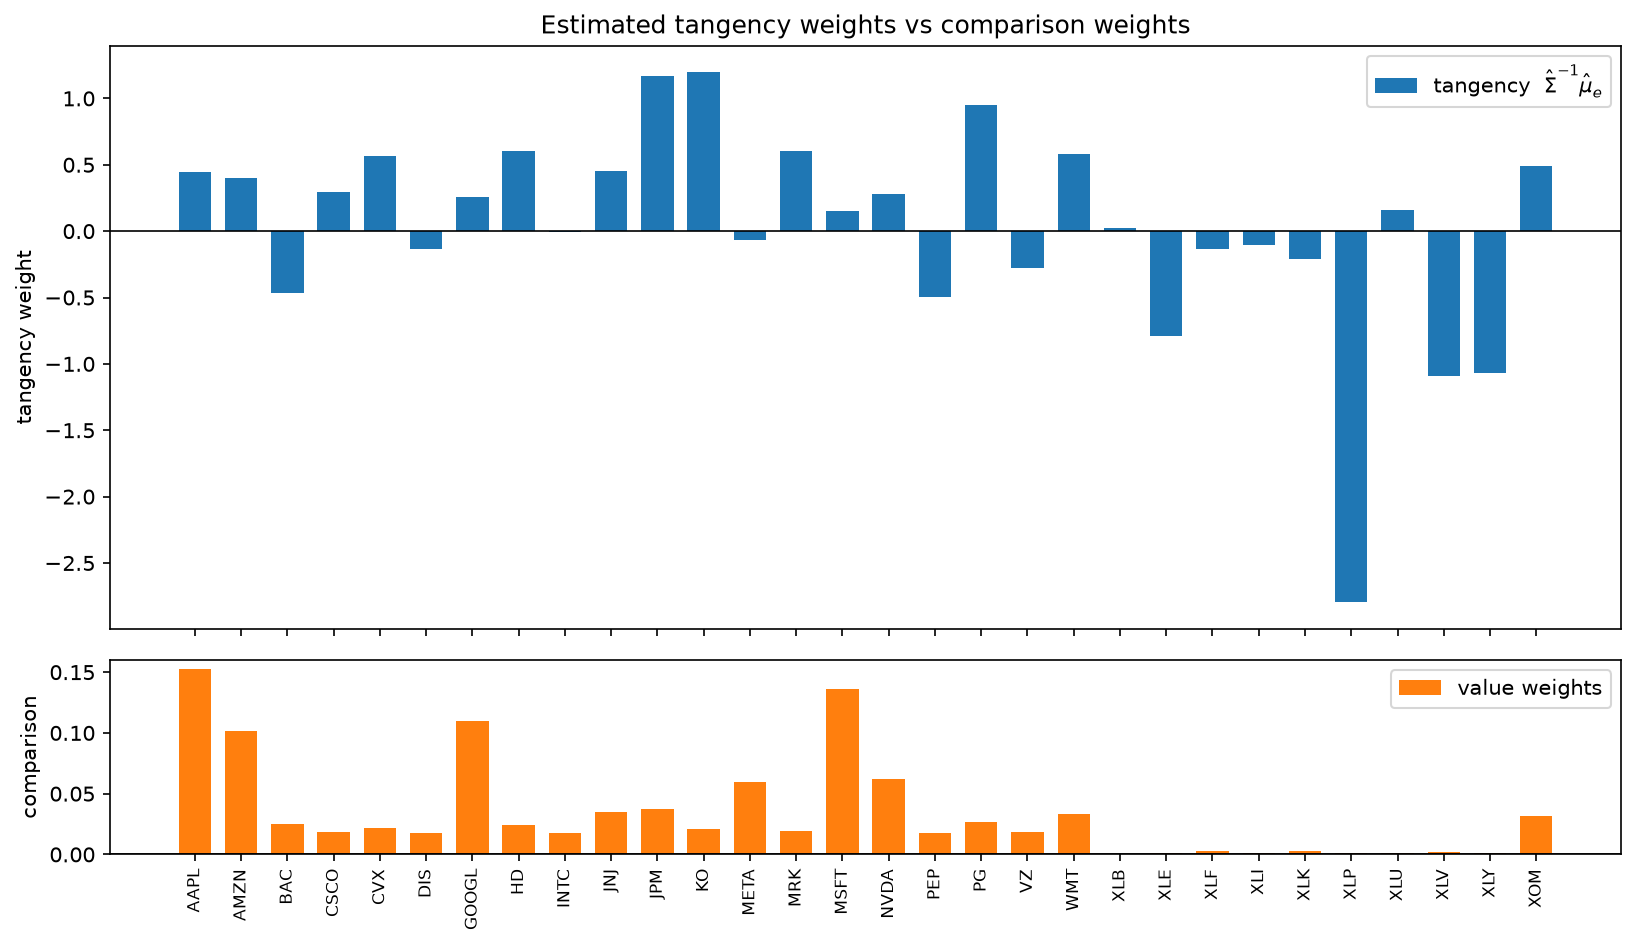

In [4]:
display(Image(filename=PORTFOLIO[PRIMARY].output_paths["weights"]))

In [5]:
w = PORTFOLIO[PRIMARY].weights
w.loc[w["tangency"].abs().sort_values(ascending=False).index].head(6).round(3)

,tangency,comparison
XLP,-2.797,0.001
KO,1.196,0.021
JPM,1.167,0.038
XLV,-1.091,0.002
XLY,-1.072,0.001
PG,0.949,0.026


**Takeaway (1b).** The tangency portfolio takes an enormous short in one name
(−280%) and large longs in others (+120%) while the value benchmark holds small
positive weights throughout. Inverting a noisy `Σ̂` and amplifying a noisy `μ̂`
produces a portfolio that is arithmetically optimal and economically absurd —
exactly the estimation error Weeks 2–3 warn about.

### (1c) How stable are the weights?

In [6]:
print(f"first-/second-half weight correlation: {PORTFOLIO[PRIMARY].weight_correlation:.2f}")
PORTFOLIO[PRIMARY].drift

first-/second-half weight correlation: 0.35


,first half,second half,full sample
AAPL,0.127,1.346,0.449
AMZN,-0.043,0.111,0.404
BAC,-0.110,-2.978,-0.467
CSCO,0.285,0.508,0.297
CVX,0.572,-0.071,0.564
DIS,0.223,-0.049,-0.134
GOOGL,0.172,0.691,0.254
HD,0.234,1.416,0.604
INTC,0.049,0.178,-0.008
JNJ,-0.297,1.470,0.456


**Takeaway (1c).** The same theory on the same assets, estimated on two halves of
the same sample, gives weight vectors correlated at only 0.35. The full-sample
extreme positions are not a stable feature of the data; they are a property of one
realisation of the noise.

### Cross-market check

In [7]:
pd.DataFrame(
    {
        u: {
            "assets": RETURNS[u].shape[1],
            "largest |tangency| weight": float(PORTFOLIO[u].most_extreme_weight),
            "half-sample weight correlation": float(PORTFOLIO[u].weight_correlation),
        }
        for u in UNIVERSES
    }
).T.round(3)

,assets,largest |tangency| weight,half-sample weight correlation
us,30.0,2.797,0.354
sg,29.0,0.796,-0.104


**Takeaway.** Singapore shows the same disease, worse: a smaller and less
synchronised market produces a half-sample correlation of −0.10. Estimation error
in mean–variance portfolios is not a US curiosity.

## 4. Stage 2 — The CAPM and the empirical SML

For each asset we estimate the security characteristic regression

$$R_{i,t} - R_{f,t} = \alpha_i + \beta_i\,(R_{M,t} - R_{f,t}) + \varepsilon_{i,t},$$

plot average excess return against `β̂_i` (the empirical SML) beside the
theoretical line through the origin, and test jointly whether all alphas are zero
with the Gibbons–Ross–Shanken statistic. With 30 assets we expect roughly one or
two |t(α̂)| > 2 from chance alone, so the joint test matters more than any single
t-statistic.

### (2a) Security characteristic lines

In [8]:
CAPM[PRIMARY].table[["beta", "alpha", "t_alpha", "p_alpha", "r_squared", "n"]].round(3)

,beta,alpha,t_alpha,p_alpha,r_squared,n
asset,,,,,,
AAPL,1.141,0.001,0.112,0.911,0.535,119
AMZN,1.417,-0.010,-1.777,0.078,0.631,119
BAC,0.953,-0.003,-0.491,0.624,0.339,119
CSCO,0.773,-0.001,-0.191,0.849,0.295,119
CVX,0.575,-0.000,-0.025,0.980,0.124,119
DIS,1.035,-0.016,-2.288,0.024,0.351,119
GOOGL,1.119,-0.002,-0.416,0.678,0.527,119
HD,0.693,-0.003,-0.560,0.577,0.279,119
INTC,1.243,-0.007,-0.507,0.613,0.167,119


**Takeaway (2a).** Betas are tightly estimated (mostly between 0.5 and 1.5) but
the alphas are noisy: only 2 of 30 reach |t| > 2, about what chance delivers.
The regression explains a large share of monthly variation (`R²` often above
0.5), which is why the CAPM is useful for risk even when it fails on return.

### (2b) The empirical SML

US


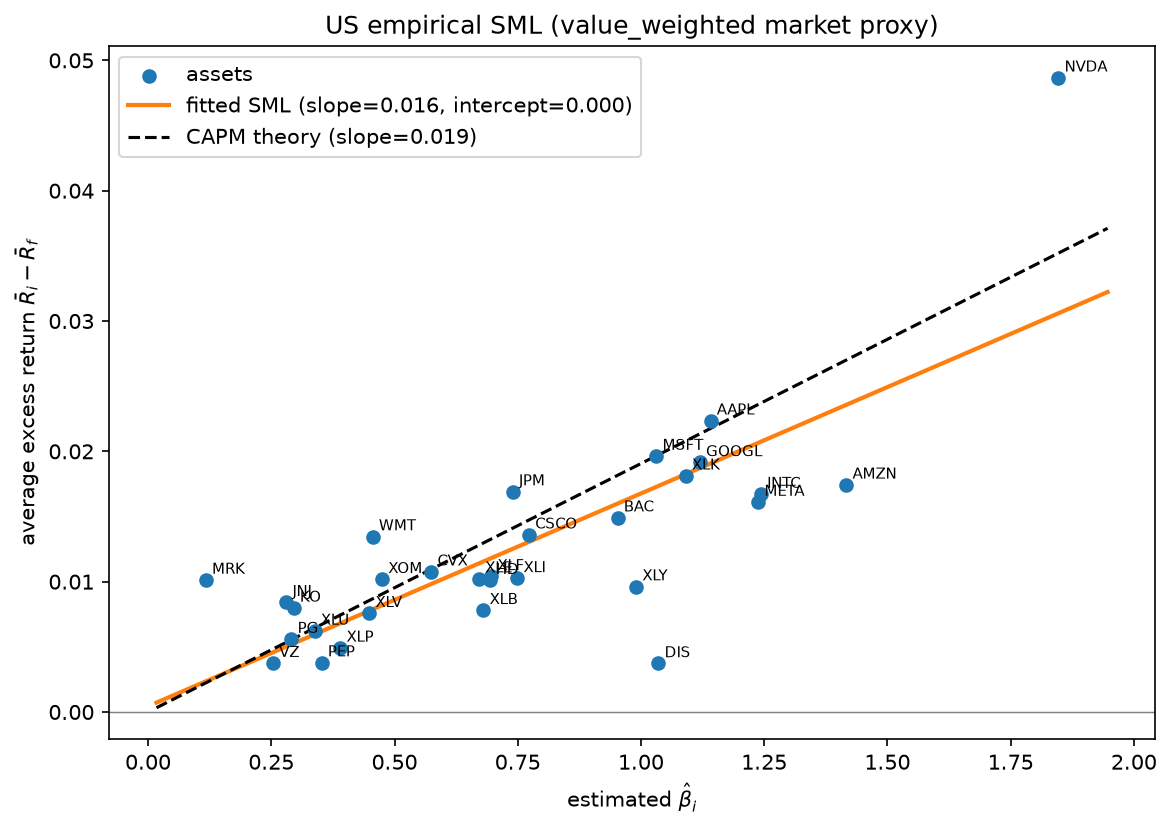

SG


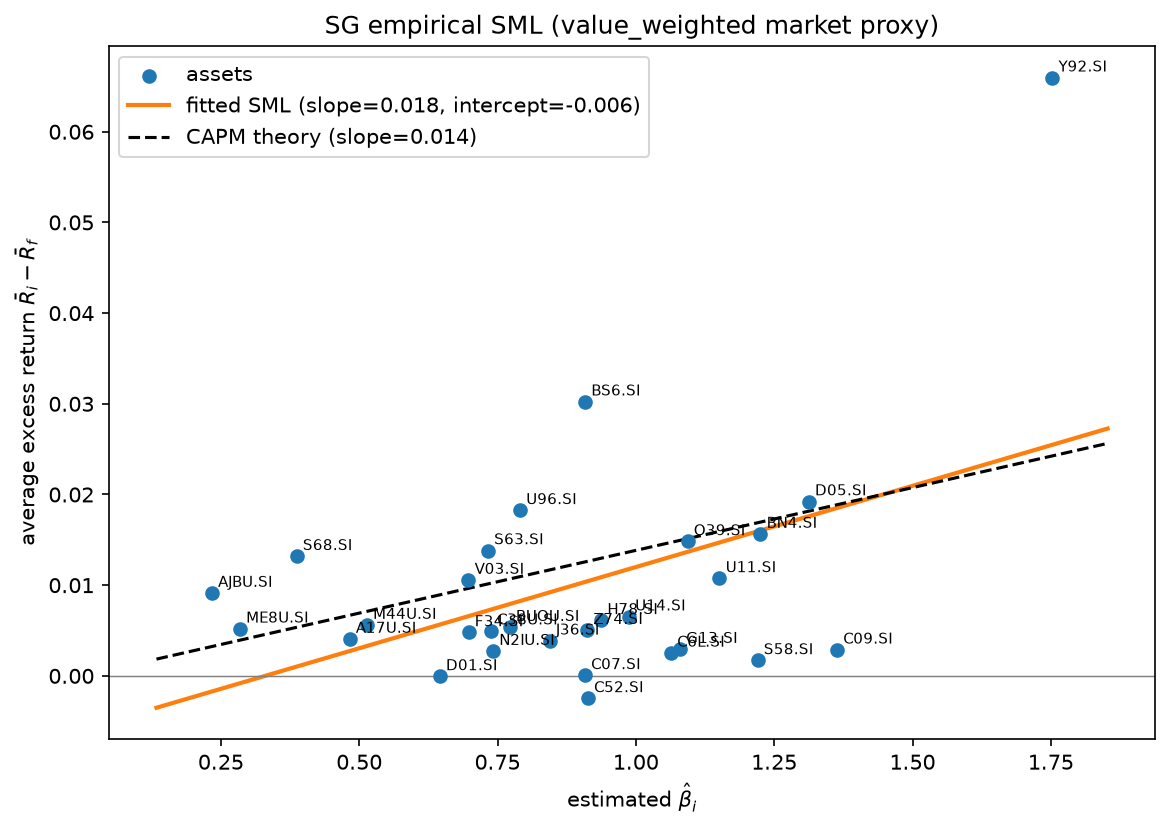

In [9]:
for u in UNIVERSES:
    print(u.upper())
    display(Image(filename=CAPM[u].output_paths["sml"]))

**Takeaway (2b).** In the US the points scatter around a line noticeably flatter
than the theoretical one; in Singapore the fitted line is steeper and sits below
the origin. If the CAPM held, every point would lie on the dashed line — the
visible scatter is the pricing error.

### (2c) Are all alphas zero?

In [10]:
pd.DataFrame(
    {
        u: {
            "assets": int(c.fit.n),
            "alphas p<0.05": int((c.table["p_alpha"] < 0.05).sum()),
            "expected by chance": round(0.05 * len(c.table), 1),
            "GRS F": c.grs["f_stat"],
            "GRS p": c.grs["p_value"],
        }
        for u, c in CAPM.items()
    }
).T.round(3)

,assets,alphas p<0.05,expected by chance,GRS F,GRS p
us,30.0,2.0,1.5,1.008,0.469
sg,29.0,6.0,1.5,1.461,0.091


**Takeaway (2c).** In the US the joint test comfortably fails to reject
(p = 0.47) and the significant count matches the chance count. Singapore is
marginal (p = 0.09) with 6 significant alphas — enough to keep watching, not
enough to declare the CAPM dead, and consistent with a smaller, noisier sample.

### (2d) Fitted versus theoretical SML

In [11]:
pd.DataFrame(
    {
        u: {
            "fitted slope": c.fit.slope,
            "theoretical slope": c.fit.theoretical_slope,
            "fitted intercept": c.fit.intercept,
            "cross-sectional R2": c.fit.r_squared,
        }
        for u, c in CAPM.items()
    }
).T.round(4)

,fitted slope,theoretical slope,fitted intercept,cross-sectional R2
us,0.0163,0.0191,0.0004,0.6100
sg,0.0179,0.0138,-0.0059,0.2166


**Takeaway (2d).** The fitted intercept should be zero and the slope should equal
the average market excess return. The US intercept is close to zero but the slope
is too flat; Singapore's intercept is negative. The classic failure signature —
a flat SML and a high intercept — appears here as a flat US line and a
mispriced offshore line.

## 5. Robustness — the market proxy (Roll)

Roll's critique: the CAPM is a statement about the *true* market portfolio, which
is unobservable. Any test uses a proxy, and its failures may be the proxy's, not
the theory's. We re-estimate the US CAPM with a second, external proxy — the
Fama–French market factor. Because that series is published with a one-month lag,
the comparison uses the common sample (118 months).

**Exhibit 5 — same assets, two market proxies.**

In [12]:
pd.DataFrame(
    {
        m: {
            "fitted slope": r.fit.slope,
            "theoretical slope": r.fit.theoretical_slope,
            "beta min": r.table["beta"].min(),
            "beta max": r.table["beta"].max(),
            "alphas p<0.05": int((r.table["p_alpha"] < 0.05).sum()),
            "GRS p": r.grs["p_value"],
        }
        for m, r in PROXY.items()
    }
).T.round(3)

,fitted slope,theoretical slope,beta min,beta max,alphas p<0.05,GRS p
value_weighted,0.016,0.019,0.117,1.847,2.0,0.469
ff_market,0.015,0.011,0.254,1.749,1.0,0.190


**Takeaway (5).** Changing only the market proxy moves the estimated betas and
halves the GRS p-value (0.47 → 0.19) without touching the assets. A conclusion
about whether the CAPM "works" is partly a conclusion about the index chosen to
represent the market — which is why the proxy deserves a paragraph in any honest
test.

## 6. What we would tell the committee

**Hold the value-weighted index; do not hold the raw tangency portfolio.** The
estimated tangency weights are dominated by estimation error (Section 3): they are
unstable across subsamples and economically indefensible. A committee asked to
believe the textbook is better served by the index, which needs no estimated
inputs.

**If we tilt at all, tilt with a leash.** The theory says something in between is
optimal when inputs are uncertain. Shrinkage of `μ̂`/`Σ̂` or a no-short-sale
constraint tames the extremes and is the responsible way to express any genuine
view. The data does not argue for abandoning mean–variance; it argues for
regularising it.

**Trust the risk model, doubt the return model.** The CAPM's betas are stable and
explain a large share of monthly variation; its alphas are not jointly
distinguishable from zero in the US. Use it to measure and budget risk, not to
pick winners.

**The result we trust least.** The Singapore CAPM's marginal GRS rejection
(p = 0.09). It rests on 29 names, a small and correlated market, and a
survivorship-biased constituent list; we would not build a strategy on it. We
report it as a cross-market echo, not as evidence of a tradable anomaly.

## 7. Caveats and limitations

**Survivorship.** Both universes are today's index members backfilled ten years.
Failed or delisted firms are absent, so average returns and Sharpe ratios are
biased upward, and the SML may look better than it should. This biases *against*
finding anomalies, if anything.

**Data quality.** Adjusted closes are a total-return proxy with vendor
adjustments, not an audited return series. Point-in-time market caps are exact
where Yahoo has share history and approximated with the earliest known count
elsewhere.

**Sample length.** 119 monthly observations is enough to estimate risk well and
returns poorly — which is the whole story. A longer sample would shrink the
standard errors on alpha but would span a different interest-rate and market
regime.

**Proxy dependence.** As Section 5 shows, the CAPM verdict is sensitive to the
market proxy. Our default cap-weighted composite is a reasonable stand-in for the
US market but not the true market portfolio, and is not constructed from the
correct free-float weights.

**Not tested here.** Transaction costs, taxes, currency (Singapore returns are
unhedged SGD), and the statistical significance of the tangency-vs-index
comparison itself.

## 8. Appendix — reproducibility and references

**Reproducing the report.** From the repository root:

```bash
uv sync --extra notebook
uv run jupyter lab notebooks/report.ipynb     # then: Kernel ▸ Restart & Run All
uv run pytest                                  # 50+ tests, 90%+ coverage
```

The notebook rebuilds every exhibit from the committed raw CSVs; nothing is
downloaded and no output is checked in by hand. Generated exhibits land under
`outputs/` (US and Singapore portfolio exhibits in `outputs/us/` and
`outputs/sg/`; CAPM exhibits as `capm_<universe>_<proxy>_*`).

**Data sources.** Yahoo Finance adjusted closes (total-return proxy); Ken French
Data Library (Fama–French factors and the US risk-free rate); Monetary Authority
of Singapore (daily SORA, compounded monthly as the SGD risk-free rate; raw export
and transformation documented in `data/rf_sg_monthly.source.txt`).

**AI tools.** *[To complete before submission per the course ground rules.]*

**Contribution statement.** *[Team names and contributions, signed.]*

**References.** Fama and French (1993); Gibbons, Ross and Shanken (1989); Roll
(1977); DeMiguel, Garlappi and Uppal (2009); Berk and DeMarzo, *Corporate
Finance*, chapters on portfolio theory and the CAPM.